# Из чего будет состоять новостной индекс

Посмотрим, что лежит в Telegram и trade, какие свойства текста влияют на поиск и где
нужна дополнительная проверка. Начинаем с исходных файлов из манифестов. Trade XLSX
уже прошёл техническую очистку. [Отчёт с графиками](README.md)

In [1]:
import csv
import hashlib
import json
import re
import sqlite3
import sys
from collections import Counter, defaultdict
from pathlib import Path
from urllib.parse import urlsplit

import matplotlib.pyplot as plt
import pandas as pd
from IPython import get_ipython
from IPython.display import display
from lingua import LanguageDetectorBuilder

root = Path.cwd()
if not (root / "docs/reference").is_dir():
    root = root.parent
sys.path.insert(0, str(root))

from scripts.import_trade_news import rows, uri_url  # noqa: E402

get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams["font.family"] = "DejaVu Sans"


def source_file(manifest):
    entry = json.loads((root / "docs/reference" / manifest).read_text())["files"][0]
    path = root / entry["path"]
    if not path.is_file():
        raise FileNotFoundError(f"Положите файл снимка по пути {path}.")
    with path.open("rb") as file:
        sha256 = hashlib.file_digest(file, "sha256").hexdigest()
    if sha256 != entry["sha256"]:
        raise ValueError(f"Файл {path} отличается от снимка в {manifest}.")
    return path


telegram_path = source_file("telegram_all12.json")
trade_path = source_file("trade_news_full.json")

## Что в файлах

В Telegram строка соответствует посту или подписи. Экспортёр пропускал посты без текста.
Trade — собранные с веб-сайтов тексты торговых новостей. В XLSX строка имеет UUID, а один адрес может встречаться несколько раз. Сравниваем веб-публикации
по URI. Перед объединением проверяем, что у одного URI одинаковы текст и метка языка.

In [2]:
tg = pd.read_json(telegram_path, lines=True, convert_dates=False)
tg_meta = pd.json_normalize(tg.pop("metadata"), max_level=0)
tg["channel"] = tg_meta["channel_username"]
tg["published"] = pd.to_datetime(tg["published_at"], utc=True)
tg["month"] = tg["published"].dt.strftime("%Y-%m")

trade = pd.DataFrame(row for _, row in rows(trade_path))
trade["uri"] = trade["url"].map(uri_url)
trade["domain"] = trade["uri"].map(lambda url: urlsplit(url).hostname)
same_url = trade.loc[trade["uri"].duplicated(keep=False)].groupby("uri")
assert same_url[["text", "orig_lang"]].nunique().le(1).all().all()
web = trade.drop_duplicates("uri")

display(
    pd.DataFrame(
        {
            "Строк или постов": [len(tg), len(trade)],
            "Уникальных исходных ID": [tg["id"].nunique(), trade["id"].nunique()],
            "Уникальных адресов": [tg["url"].nunique(), web["uri"].nunique()],
            "Источников": [tg["channel"].nunique(), web["domain"].nunique()],
            "Пустых текстов": [
                tg["text"].str.strip().eq("").sum(),
                trade["text"].str.strip().eq("").sum(),
            ],
        },
        index=["Telegram", "Trade XLSX"],
    )
)
display(
    pd.Series(
        {
            "Повторяющихся URI": same_url.ngroups,
            "URI с разными dates": same_url["dates"].nunique().gt(1).sum(),
        }
    ).to_frame("Групп")
)

,Строк или постов,Уникальных исходных ID,Уникальных адресов,Источников,Пустых текстов
Telegram,89832,89832,89832,12,0
Trade XLSX,103190,103190,101963,331,0


,Групп
Повторяющихся URI,793
URI с разными dates,491


У одного веб-текста встречаются разные даты и метки. Для индекса достаточно одной
копии текста, а для аудита нужна связь с исходными строками. Заголовок можно
пробовать как отдельное поле поиска. В строке XLSX 34 заголовок сообщает рост
пошлины на 1,5%, а основной текст — на 52,3%, то есть примерно в полтора раза.
Числа для ответа нужно сверять с основным текстом.
[Статья](https://www.interfax.ru/business/867929)

In [3]:
raw_fields = trade.drop(columns=["uri", "domain"])
display(raw_fields.apply(lambda column: column.str.strip().eq("").sum()).to_frame("Пусто в XLSX"))
display(trade["orig_lang"].replace("", "unknown").value_counts().to_frame("Строк XLSX"))

language_text = tg["text"].str.replace(r"https?://\S+|@\w+", " ", regex=True).str[:600]
has_letters = language_text.map(lambda text: sum(c.isalpha() for c in text) >= 30)
detector = (
    LanguageDetectorBuilder.from_all_languages()
    .with_low_accuracy_mode()
    .with_minimum_relative_distance(0.15)
    .build()
)
language = pd.Series("unknown", index=tg.index)
language.loc[has_letters] = [
    guess.iso_code_639_1.name.lower() if guess else "unknown"
    for guess in detector.detect_languages_in_parallel_of(language_text.loc[has_letters].tolist())
]
language = language.where(language.isin(["ru", "unknown"]), "прочие")
display(language.value_counts().to_frame("Оценка языка Telegram"))
del detector, language_text

,Пусто в XLSX
id,0
text,0
title,9
title_en,14
title_orig_lang,101622
orig_lang,7
dates,0
classes,0
itc_codes,50
locations,7


,Строк XLSX
orig_lang,
ru,61999
en,39614
pt,1300
fr,270
unknown,7


,Оценка языка Telegram
ru,89167
unknown,609
прочие,56


## Что показывают счётчики Telegram

Суммируем реакции по видам. Пустой список даёт ноль, отсутствующее поле остаётся
пропуском. Ответы считаем комментариями только при replies_are_comments=true.
Возраст поста считаем на момент наблюдения. Сравним просмотры в одной группе
возраста от 30 до 90 дней, не включая 90-й день.

In [4]:
observed = pd.to_datetime(tg_meta["observed_at"], format="mixed", utc=True)
reactions = tg_meta["reactions"].map(
    lambda items: sum(item["count"] for item in items) if isinstance(items, list) else None
)
comments = tg_meta["replies_count"].where(tg_meta["replies_are_comments"].eq(True))
counts = pd.DataFrame(
    {
        "Просмотры": tg_meta["views"],
        "Пересылки": tg_meta["forwards"],
        "Реакции": reactions,
        "Комментарии": comments,
    }
)
display(
    pd.DataFrame(
        {
            "Записано": counts.count(),
            "Доля, %": counts.notna().mean().mul(100).round(1),
            "Нулей": counts.eq(0).sum(),
            "Медиана": counts.median(),
        }
    )
)

age_days = (observed - tg["published"]) / pd.Timedelta(days=1)
cohort = tg.loc[age_days.between(30, 90, inclusive="left"), ["id", "channel"]].join(
    counts[["Просмотры", "Пересылки"]]
)
top = cohort.sort_values(["Просмотры", "id"], ascending=[False, True]).head(len(cohort) // 10)
channel_coverage = counts[["Реакции", "Комментарии"]].notna().groupby(tg["channel"]).mean()
channel_coverage = channel_coverage.mul(100).round(1).add_suffix(", %")
channel_stats = cohort.groupby("channel").agg(
    постов_30_90=("id", "size"),
    медиана_просмотров=("Просмотры", "median"),
    медиана_пересылок=("Пересылки", "median"),
)
channel_stats["В верхнем дециле"] = (
    top["channel"].value_counts().reindex(channel_stats.index, fill_value=0)
)
display(channel_coverage.join(channel_stats).sort_values("медиана_просмотров", ascending=False))

leading_channels = top["channel"].value_counts().head(2).index
print(
    "Постов из двух ведущих каналов:",
    cohort["channel"].isin(leading_channels).sum(),
    "из",
    len(cohort),
)
print(
    "Из этих же каналов в верхнем дециле:",
    top["channel"].isin(leading_channels).sum(),
    "из",
    len(top),
)

,Записано,"Доля, %",Нулей,Медиана
Просмотры,89832,100.0,0,66641.0
Пересылки,89832,100.0,263,128.0
Реакции,49399,55.0,13,57.0
Комментарии,27233,30.3,19860,0.0


,"Реакции, %","Комментарии, %",постов_30_90,медиана_просмотров,медиана_пересылок,В верхнем дециле
channel,,,,,,
ecotopor,99.7,0.0,545,309716.0,2520.0,542
ostorozhno_novosti,0.0,0.0,1245,247610.0,589.0,904
meduzalive,0.0,0.0,2475,178692.0,239.0,36
banksta,0.0,0.0,3013,68103.0,264.0,0
fontankaspb,99.4,99.1,1898,45040.0,102.0,0
faridaily24,100.0,100.0,40,43086.0,278.5,0
bitkogan,98.5,0.0,161,31033.0,61.0,0
thebell_io,100.0,99.9,688,16082.0,39.0,0
selfinvestor,100.0,99.6,712,9944.0,26.0,0


Постов из двух ведущих каналов: 1790 из 14822
Из этих же каналов в верхнем дециле: 1446 из 1482


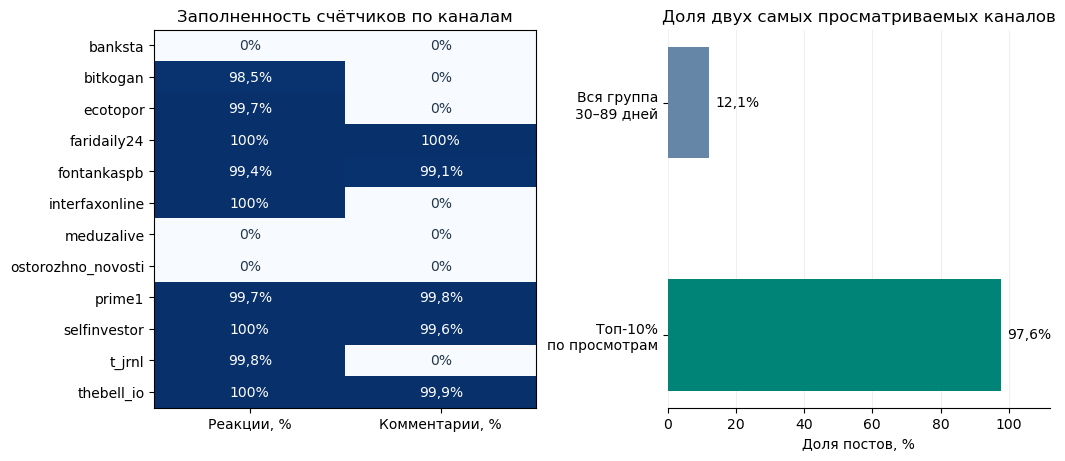

In [5]:
coverage = channel_coverage.sort_index()
channel_shares = [
    cohort["channel"].isin(leading_channels).mean() * 100,
    top["channel"].isin(leading_channels).mean() * 100,
]
fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(10.5, 4.5), layout="constrained")

ax_left.imshow(coverage, vmin=0, vmax=100, cmap="Blues", aspect="auto")
ax_left.set(
    title="Заполненность счётчиков по каналам",
    xticks=range(len(coverage.columns)),
    xticklabels=coverage.columns,
    yticks=range(len(coverage)),
    yticklabels=coverage.index,
)
for y, row in enumerate(coverage.to_numpy()):
    for x, value in enumerate(row):
        label = f"{value:g}%".replace(".", ",")
        ax_left.text(
            x, y, label, ha="center", va="center", color="white" if value >= 70 else "#22374a"
        )

bars = ax_right.barh(
    ["Вся группа\n30–89 дней", "Топ-10%\nпо просмотрам"],
    channel_shares,
    color=["#6686A8", "#008477"],
    height=0.48,
)
ax_right.set(
    title="Доля двух самых просматриваемых каналов", xlabel="Доля постов, %", xlim=(0, 112)
)
ax_right.invert_yaxis()
ax_right.set_axisbelow(True)
ax_right.grid(axis="x", alpha=0.2)
ax_right.spines[["top", "right", "left"]].set_visible(False)
ax_right.bar_label(bars, labels=[f"{v:.1f}%".replace(".", ",") for v in channel_shares], padding=5)
plt.show()

Счётчики зависят от канала и времени наблюдения. Реакции отсутствуют во всех постах
трёх каналов, комментарии — семи. У двух каналов 12,1% постов сравниваемого возраста
и 97,6% верхнего дециля по просмотрам. Эти поля подходят для анализа смещения выдачи.
Если проверяем их в ранжировании, нужна разметка релевантности и счётчики,
которые уже были известны в момент запроса.

## Помогут ли метки Trade искать новости

Одна строка XLSX может содержать несколько тем, географических меток и кодов товара.
Считаем уникальные значения в каждой строке. В повторах одного URI сравниваем наборы
меток без учёта порядка. Для русскоязычных строк сопоставляем метку «Внешняя торговля»
с простым поиском слов об экспорте, импорте и внешней торговле.

In [6]:
def class_tags(value):
    items = next(csv.reader([value[1:-1]], escapechar="\\"))
    return frozenset(item.strip() for item in items if item.strip())


code_pattern = r"(?:^|;;)\s*(\d+)\s*[-–—]"
labels = pd.DataFrame(
    {
        "classes": trade["classes"].map(class_tags),
        "locations": trade["locations"].map(
            lambda value: frozenset(item.strip() for item in value.split(",") if item.strip())
        ),
        "itc_codes": trade["itc_codes"].str.findall(code_pattern).map(frozenset),
    }
)
label_count = labels.map(len)
repeated_uri = trade["uri"].duplicated(keep=False)
conflicts = labels.loc[repeated_uri].groupby(trade["uri"]).nunique().gt(1).sum()
display(
    pd.DataFrame(
        {
            "Строк без меток": label_count.eq(0).sum(),
            "Строк с несколькими метками": label_count.gt(1).sum(),
            "Разных меток": labels.apply(lambda field: field.explode().nunique()),
            "Повторных URI с разными наборами": conflicts,
        }
    )
)

product = trade["product"].str.strip()
codes_en = trade["itc_codes_en"].str.findall(code_pattern).map(frozenset)
both_codes = codes_en.map(bool) & labels["itc_codes"].map(bool)
display(
    pd.Series(
        {
            "Пустой product": product.eq("").sum(),
            "Служебное значение CLASSIFIED_BY_TEXT": product.eq("CLASSIFIED_BY_TEXT").sum(),
            "Строки с кодом, начинающимся с нуля": labels["itc_codes"]
            .map(lambda codes: any(code.startswith("0") and len(code) > 1 for code in codes))
            .sum(),
            "Есть оба набора ITC, русский и английский": both_codes.sum(),
            "Наборы ITC различаются среди заполненных": (
                labels.loc[both_codes, "itc_codes"] != codes_en.loc[both_codes]
            ).sum(),
        }
    ).to_frame("Строк XLSX")
)

ru = trade["orig_lang"].eq("ru")
trade_marker = r"\b(?:экспорт\w*|импорт\w*|внешн\w+\s+торговл\w*|внешнеторгов\w*)\b"
marker_in_text = trade.loc[ru, "text"].str.contains(trade_marker, case=False)
trade_tag = labels.loc[ru, "classes"].map(lambda tags: "Внешняя торговля" in tags)
comparison = pd.crosstab(trade_tag, marker_in_text)
comparison.index = ["Без метки", "С меткой"]
comparison.columns = ["Нет маркера в тексте", "Есть маркер в тексте"]
comparison["С маркером, %"] = (
    comparison["Есть маркер в тексте"] / comparison.sum(axis=1) * 100
).round(1)
display(comparison)

,Строк без меток,Строк с несколькими метками,Разных меток,Повторных URI с разными наборами
classes,7,31734,6,258
locations,7,89862,242,317
itc_codes,51,35251,78,348


,Строк XLSX
Пустой product,26076
Служебное значение CLASSIFIED_BY_TEXT,2552
"Строки с кодом, начинающимся с нуля",15718
"Есть оба набора ITC, русский и английский",103104
Наборы ITC различаются среди заполненных,0


,Нет маркера в тексте,Есть маркер в тексте,"С маркером, %"
Без метки,11626,3270,22.0
С меткой,15824,31279,66.4


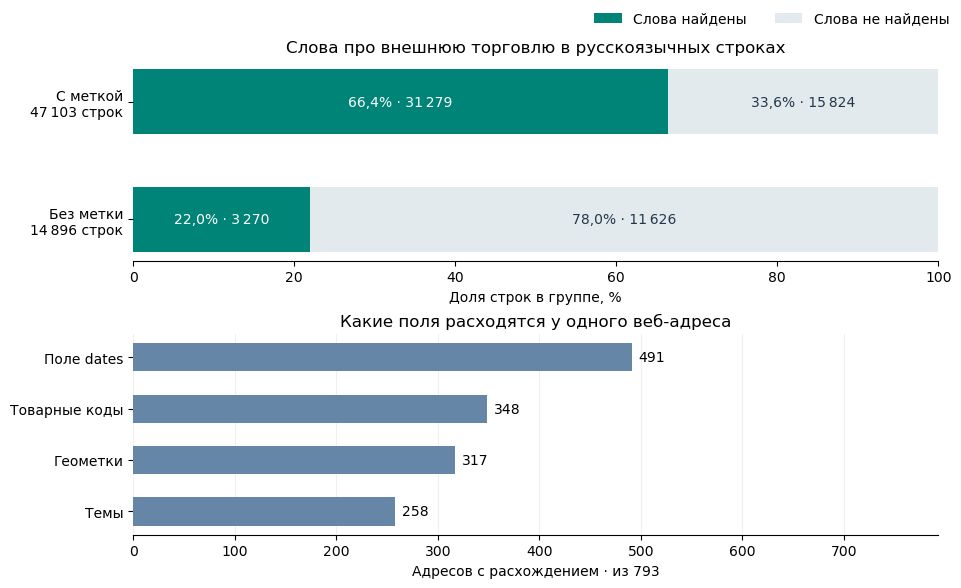

In [7]:
marker_counts = comparison.loc[
    ["С меткой", "Без метки"], ["Есть маркер в тексте", "Нет маркера в тексте"]
]
totals = marker_counts.sum(axis=1)
shares = marker_counts.div(totals, axis=0).mul(100)
group_names = [f"{name}\n{total:,} строк".replace(",", " ") for name, total in totals.items()]
fig, (ax_top, ax_bottom) = plt.subplots(2, 1, figsize=(9.5, 5.8), layout="constrained")

left = pd.Series(0.0, index=shares.index)
for column, color, text_color, legend in [
    ("Есть маркер в тексте", "#008477", "white", "Слова найдены"),
    ("Нет маркера в тексте", "#e3eaed", "#22374a", "Слова не найдены"),
]:
    bars = ax_top.barh(
        group_names, shares[column], left=left, height=0.55, color=color, label=legend
    )
    bar_labels = [
        f"{share:.1f}%".replace(".", ",") + f" · {n:,}".replace(",", " ")
        for share, n in zip(shares[column], marker_counts[column], strict=True)
    ]
    ax_top.bar_label(bars, labels=bar_labels, label_type="center", color=text_color)
    left += shares[column]
ax_top.set(
    title="Слова про внешнюю торговлю в русскоязычных строках",
    xlabel="Доля строк в группе, %",
    xlim=(0, 100),
)
ax_top.invert_yaxis()
fig.legend(loc="outside upper right", frameon=False, ncol=2)

differences = conflicts.rename(
    index={
        "classes": "Темы",
        "locations": "Геометки",
        "itc_codes": "Товарные коды",
    }
)
differences["Поле dates"] = same_url["dates"].nunique().gt(1).sum()
bars = ax_bottom.barh(
    differences.sort_values().index, differences.sort_values(), color="#6686A8", height=0.55
)
ax_bottom.set(
    title="Какие поля расходятся у одного веб-адреса",
    xlabel=f"Адресов с расхождением · из {same_url.ngroups}",
    xlim=(0, same_url.ngroups),
)
ax_bottom.bar_label(bars, padding=5)
ax_bottom.set_axisbelow(True)
ax_bottom.grid(axis="x", alpha=0.2)

for ax in (ax_top, ax_bottom):
    ax.spines[["top", "right", "left"]].set_visible(False)
plt.show()

Среди 47 103 русскоязычных строк с меткой «Внешняя торговля» нашли слова про
экспорт, импорт или внешнюю торговлю в 31 279 строках. Среди 14 896 строк
без метки нашли 3 270 таких строк. Они исчезнут из поиска при обязательном
фильтре по метке. Это кандидаты для разметки, а её качество проверяем на запросах.

Один и тот же текст может попасть в XLSX несколько раз под одним веб-адресом,
но с разными темами, странами или кодами товаров. Индексируем текст один раз,
а наборы меток сохраняем вместе с ID исходных строк. Коды храним строками, чтобы
сохранить ведущие нули. У product бывают пустые и служебные значения.

## Какие периоды можно сравнивать

У Telegram есть время публикации. Поле dates в XLSX показывает покрытие выгрузки
и требует подтверждения, прежде чем использовать его как дату публикации.

month,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10,2026-11,всего
channel,,,,,,,,,,,,,,
banksta,989,1458,1428,1411,1839,1602,1419,1683,1466,1468,1538,1639,389,18329
interfaxonline,818,1261,1097,1012,1352,1358,1305,1483,1488,1210,1369,1470,302,15525
meduzalive,846,1191,1104,1209,1420,1221,1164,1224,1340,1268,1229,1245,283,14744
fontankaspb,684,1060,835,915,1005,876,913,906,960,920,924,1060,226,11284
prime1,485,734,562,444,651,686,646,554,697,552,616,558,117,7302
ostorozhno_novosti,360,578,488,553,778,563,570,679,632,645,612,651,132,7241
selfinvestor,329,421,323,332,366,400,335,375,378,319,367,400,91,4436
thebell_io,251,355,288,318,385,366,286,363,381,303,365,368,81,4110
ecotopor,291,367,328,309,295,371,329,331,299,277,269,308,71,3845


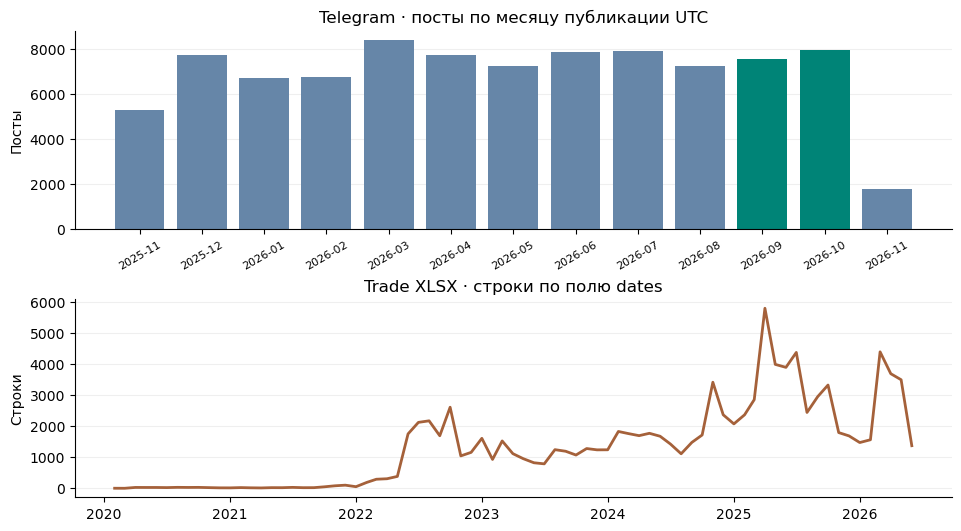

In [8]:
tg_months = pd.crosstab(tg["channel"], tg["month"])
trade_months = trade.groupby(pd.PeriodIndex(trade["dates"].str[:7], freq="M")).size()
trade_months = trade_months.reindex(
    pd.period_range(trade_months.index.min(), trade_months.index.max(), freq="M"), fill_value=0
)
display(tg_months.assign(всего=tg_months.sum(axis=1)).sort_values("всего", ascending=False))

fig, (ax_tg, ax_web) = plt.subplots(2, 1, figsize=(9.5, 5.2), layout="constrained")
monthly = tg_months.sum()
colors = ["#008477" if month in {"2026-09", "2026-10"} else "#6686A8" for month in monthly.index]
ax_tg.bar(monthly.index, monthly, color=colors)
ax_tg.set(title="Telegram · посты по месяцу публикации UTC", ylabel="Посты")
ax_tg.tick_params(axis="x", labelsize=8, rotation=30)
ax_web.plot(trade_months.index.to_timestamp(), trade_months, color="#A5613A", linewidth=2)
ax_web.set(title="Trade XLSX · строки по полю dates", ylabel="Строки")
for ax in (ax_tg, ax_web):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
plt.show()

Сентябрь и октябрь — два последних полных месяца Telegram со всеми каналами.
Их удобно использовать для разметки вопросов. По датам trade этот период уже
вне диапазона выгрузки. Сравнение совместного поиска требует отдельно подтвердить
период покрытия у веб-публикаций.

## Какие тексты попадут в поиск

Четыре Telegram-записи состоят из одного хэндла. У trade среди одинаковых текстов
нашли шесть вариантов, где вместо статьи сохранились копирайт, cookie или интерфейс
комментариев. Исключаем только эти проверенные тексты по полному совпадению с проверенными примерами.

In [9]:
only_handle = tg["text"].str.fullmatch(r"\s*@[A-Za-z][A-Za-z0-9_]*\s*")
posts = tg.loc[~only_handle]
web_ru = web.loc[web["orig_lang"].eq("ru")]
# Эти страницы просмотрены вручную. Их text целиком состоит из шаблона сайта.
template_examples = [
    "https://rossaprimavera.ru/news/f7054e5f",
    "https://rossaprimavera.ru/news/17575292",
    "https://rossaprimavera.ru/news/2d868e71",
    "https://tass.ru/ekonomika/14936717",
    "https://1prime.ru/business/20230213/839784033.html",
    ("https://www.lesprom.com/ru/news/OptiGroup_приобрела_нидерландскую_SG_Verpakkingen_104476/"),
]
example_rows = trade["url"].isin(template_examples)
templates = trade.loc[example_rows, "text"].unique()
assert len(templates) == 6
articles = web_ru.loc[~web_ru["text"].isin(templates)]
annotation_window = posts.loc[posts["month"].isin(["2026-09", "2026-10"])]

display(
    pd.DataFrame(
        [
            ("Telegram", "Исходный экспорт", len(tg), tg["channel"].nunique()),
            ("Telegram", "Убраны одиночные хэндлы", len(posts), posts["channel"].nunique()),
            (
                "Telegram",
                "Окно разметки сентябрь–октябрь",
                len(annotation_window),
                annotation_window["channel"].nunique(),
            ),
            ("Trade", "Строки XLSX", len(trade), trade["domain"].nunique()),
            ("Trade", "Публикации по URI", len(web), web["domain"].nunique()),
            ("Trade", "С исходной меткой ru", len(web_ru), web_ru["domain"].nunique()),
            ("Trade", "Убраны шесть шаблонов", len(articles), articles["domain"].nunique()),
        ],
        columns=["Корпус", "Шаг", "Записей", "Источников"],
    )
)

,Корпус,Шаг,Записей,Источников
0,Telegram,Исходный экспорт,89832,12
1,Telegram,Убраны одиночные хэндлы,89828,12
2,Telegram,Окно разметки сентябрь–октябрь,15453,12
3,Trade,Строки XLSX,103190,331
4,Trade,Публикации по URI,101963,331
5,Trade,С исходной меткой ru,61103,180
6,Trade,Убраны шесть шаблонов,60879,180


## Насколько тексты длинные

Считаем слова через пробельные разделители. Для разбивки на фрагменты затем понадобится
токенизатор выбранной модели. В trade сравниваем русские и английские тексты отдельно.

,Корпус,Текстов,Медиана,p90,"≤30 слов, %",">400 слов, %"
0,Telegram,89828,71.0,175.0,18.4,1.1
1,Trade RU,60879,190.0,388.0,0.1,9.0
2,Trade EN,39285,374.0,786.0,0.1,44.9


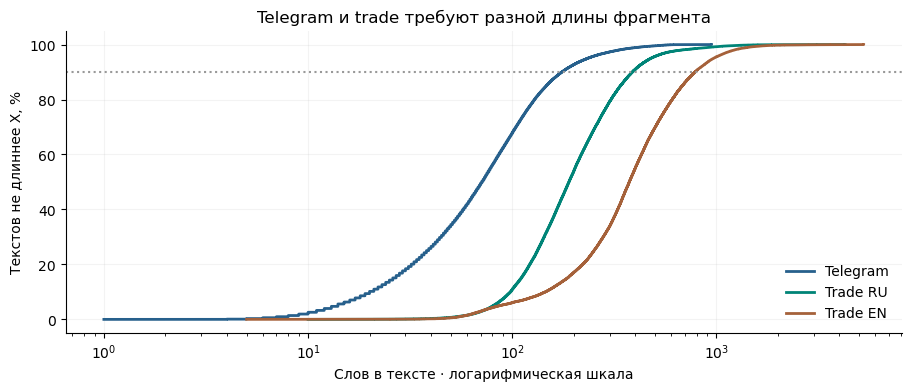

In [10]:
lengths = {
    "Telegram": posts["text"].str.split().str.len(),
    "Trade RU": articles["text"].str.split().str.len(),
    "Trade EN": web.loc[web["orig_lang"].eq("en"), "text"].str.split().str.len(),
}
display(
    pd.DataFrame(
        [
            (
                name,
                len(words),
                words.median(),
                words.quantile(0.9),
                words.le(30).mean() * 100,
                words.gt(400).mean() * 100,
            )
            for name, words in lengths.items()
        ],
        columns=["Корпус", "Текстов", "Медиана", "p90", "≤30 слов, %", ">400 слов, %"],
    ).round(1)
)

fig, ax = plt.subplots(figsize=(9, 3.8), layout="constrained")
for (name, words), color in zip(lengths.items(), ["#27608C", "#008477", "#A5613A"], strict=True):
    counts = words.value_counts().sort_index()
    ax.step(
        counts.index,
        counts.cumsum() / len(words) * 100,
        where="post",
        label=name,
        color=color,
        linewidth=2,
    )
ax.set(
    xscale="log",
    xlabel="Слов в тексте · логарифмическая шкала",
    ylabel="Текстов не длиннее X, %",
    title="Telegram и trade требуют разной длины фрагмента",
)
ax.axhline(90, color="#999999", linestyle=":")
ax.legend(loc="lower right", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.15)
plt.show()

Целый Telegram-пост — стартовая единица поиска. Для длинных веб-статей сравним
целый текст и фрагменты при одном бюджете контекста. Русский и английский срезы
имеют разную длину, поэтому порог проверяем по языкам.

## Что находится внутри текста

Каждый признак — доля документов хотя бы с одним совпадением. Считаем простые
наблюдаемые маркеры. Для числовых выражений покрытие ограничено перечисленными единицами.
Ссылки из Telegram metadata учитываем отдельно.

,Telegram,Trade RU
Число с единицей,25.6,61.1
Десятичное число с единицей,11.9,35.5
URL в тексте,3.2,1.4
Пустая строка между абзацами,85.2,2.1


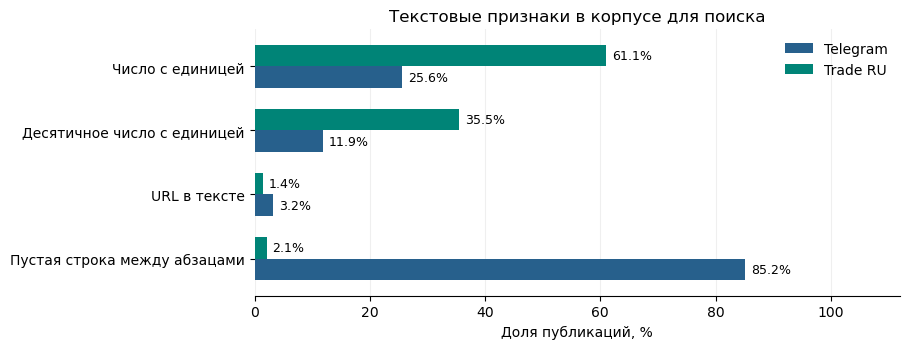

In [11]:
unit = r"(?:%|п\.\s*п\.|б\.\s*п\.|млн\b|млрд\b|трлн\b|тыс\b|руб(?:\.|л[яей])|тонн\w*)"
patterns = {
    "Число с единицей": rf"(?<![\d.,])\d+(?:[.,]\d+)?\s*{unit}",
    "Десятичное число с единицей": rf"(?<![\d.,])\d+[.,]\d+\s*{unit}",
    "URL в тексте": r"https?://\S+",
    "Пустая строка между абзацами": r"\r?\n[ \t]*\r?\n",
}
text_sets = {"Telegram": posts["text"], "Trade RU": articles["text"]}
rates = pd.DataFrame(
    {
        corpus: {
            label: texts.str.contains(pattern, case=False).mean() * 100
            for label, pattern in patterns.items()
        }
        for corpus, texts in text_sets.items()
    }
)
display(rates.round(1))
ax = rates.iloc[::-1].plot.barh(
    figsize=(9.2, 3.6), color=["#27608C", "#008477"], width=0.66, legend=True
)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f%%", padding=4, fontsize=9)
ax.set(xlim=(0, 112), xlabel="Доля публикаций, %", title="Текстовые признаки в корпусе для поиска")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

Числа и единицы часто стоят рядом и должны вместе попасть в индекс и цитату.
Абзацы размечены неравномерно. Для текста без разделителей стоит проверить
разбиение по предложениям. URL в тексте и скрытая ссылка в Telegram — разные поля.

In [12]:
last_line = tg["text"].map(lambda text: text.strip().splitlines()[-1].strip())
tails = Counter(zip(tg["channel"], last_line, strict=True)).most_common(6)
display(
    pd.DataFrame(
        [(channel, line, count) for (channel, line), count in tails],
        columns=["Канал", "Последняя строка", "Постов"],
    )
)

top_tails = {key for key, _ in tails}
has_tail = pd.Series([key in top_tails for key in zip(tg["channel"], last_line, strict=True)])
trimmed = tg["text"].copy()
trimmed.loc[has_tail] = trimmed.loc[has_tail].map(
    lambda text: "\n".join(text.strip().splitlines()[:-1])
)
brand = r"\b(?:max|макс(?:е)?)\b"
hidden_url = sum(
    any(url not in body for url in links)
    for body, links in zip(tg["text"], tg_meta["links"], strict=True)
)
display(
    pd.Series(
        {
            "Посты с одним из шести хвостов": int(has_tail.sum()),
            "Тексты с Max/Макс до удаления хвоста": tg["text"]
            .str.contains(brand, case=False)
            .sum(),
            "Тексты с Max/Макс после удаления": trimmed.str.contains(brand, case=False).sum(),
            "Посты со ссылкой в метаданных": tg_meta["links"].str.len().gt(0).sum(),
            "Посты с URL из метаданных, которого нет в тексте": hidden_url,
            "Telegram: записи с повтором полного текста": tg["text"].duplicated(keep=False).sum(),
            "Trade по URI: записи с повтором полного текста": web["text"]
            .duplicated(keep=False)
            .sum(),
        }
    ).to_frame("Записей")
)

,Канал,Последняя строка,Постов
0,interfaxonline,@interfaxonline,14251
1,meduzalive,@meduzalive,12323
2,fontankaspb,Telegram | Все каналы «Фонтанки» | Max,8976
3,prime1,Подписывайтесь на ПРАЙМ в Макс,3318
4,prime1,Подписывайтесь на ПРАЙМ в MAX,2709
5,selfinvestor,💱 Подписаться на канал | Мы в «Максе»,1765


,Записей
Посты с одним из шести хвостов,43342
Тексты с Max/Макс до удаления хвоста,20886
Тексты с Max/Макс после удаления,4211
Посты со ссылкой в метаданных,54147
"Посты с URL из метаданных, которого нет в тексте",51124
Telegram: записи с повтором полного текста,203
Trade по URI: записи с повтором полного текста,300


Одинаковые подписи заметно влияют на словарь BM25. В поисковом тексте их можно снять
по точной последней строке, сохранив оригинал для цитирования. Короткая подпись
может требовать медиа. Маркированное промо и анонсы проверяем отдельно.
[Промо](https://t.me/selfinvestor/27381) · [Анонс эфира](https://t.me/bitkogan/28629)

## Где источники пересекаются

Сначала ищем прямые ссылки из метаданных Telegram на веб-адреса. Затем ищем в
RU trade общие фрагменты с Telegram. Совпадение — два разных блока по 12 слов
после приведения регистра, замены ё на е и удаления ссылок и хэндлов. Блоки
в Telegram непересекающиеся. Общие блоки из более чем 10 постов пропускаем.

In [13]:
web_urls = set(web["uri"])
direct = set()
for post_id, links in zip(tg["id"], tg_meta["links"], strict=True):
    for link in links:
        if link.startswith(("https://", "http://")):
            try:
                url = uri_url(link)
            except ValueError:
                continue
            if url in web_urls:
                direct.add((post_id, url))


def words_for_match(text):
    text = re.sub(r"https?://\S+|(?<!\w)@\w+", " ", text)
    return re.findall(r"[^\W_]+", text.casefold().replace("ё", "е"))


anchors = defaultdict(list)
for row in posts.itertuples():
    words = words_for_match(row.text)
    for block in {tuple(words[i : i + 12]) for i in range(0, len(words) - 11, 12)}:
        anchors[block].append(row.id)
anchors = {block: ids for block, ids in anchors.items() if len(ids) <= 10}
starts = {block[0] for block in anchors}

shared = set()
for article in web_ru.itertuples():
    words = words_for_match(article.text)
    blocks = {tuple(words[i : i + 12]) for i in range(len(words) - 11) if words[i] in starts}
    matches = Counter(post_id for block in blocks for post_id in anchors.get(block, ()))
    shared.update((post_id, article.uri) for post_id, count in matches.items() if count >= 2)

display(
    pd.Series(
        {
            "Прямые ссылки": len(direct),
            "Общий текст": len(shared),
            "Оба сигнала": len(direct & shared),
            "Уникальные пары-кандидаты": len(direct | shared),
        }
    ).to_frame("Пар")
)
del anchors

,Пар
Прямые ссылки,35
Общий текст,198
Оба сигнала,7
Уникальные пары-кандидаты,226


226 пар помогают искать перепечатки. Один материал Интерфакса повторяет значения
долей расчётов в посте и статье. Сводки Brent также совпадают по фразам у разных
дат и цен. Поэтому проверяем событие, период и происхождение перед группировкой.
[Пост о расчётах](https://t.me/interfaxonline/73062) · [Статья](https://www.interfax.ru/business/1090465)

## Время и числовой поиск

Публикация, правка и наблюдение версии — разные даты. Например, Фонтанка уточнила
сумму закупки до 445 тыс. руб. Для ответа о сумме до правки нужна прежняя редакция.
[Исправление](https://t.me/fontankaspb/106955)

In [14]:
edited = pd.to_datetime(tg_meta["edited_at"], format="mixed", utc=True)
display(
    pd.Series(
        {
            "Метка правки": edited.notna().sum(),
            "Правка больше чем через сутки": (edited - tg["published"]).gt("1d").sum(),
            "Версий, наблюдавшихся до 1 ноября UTC": observed.lt("2026-11-01").sum(),
        }
    ).to_frame("Постов")
)

with sqlite3.connect(":memory:") as db:
    db.execute("CREATE VIRTUAL TABLE posts USING fts5(text, tokenize='unicode61')")
    db.executemany("INSERT INTO posts VALUES (?)", ((body,) for body in annotation_window["text"]))
    exact = dict(db.execute("SELECT rowid, text FROM posts WHERE posts MATCH ?", ('"85%"',)))
    plain = dict(db.execute("SELECT rowid, text FROM posts WHERE posts MATCH ?", ('"85"',)))
    print(f"85%: {len(exact)}, 85: {len(plain)}. Наборы совпадают: {exact.keys() == plain.keys()}.")
    percent = re.compile(r"(?<!\d[.,])(?<!\d)85\s*%")
    print(
        "Из них с самостоятельным числом 85%:", sum(bool(percent.search(t)) for t in exact.values())
    )

,Постов
Метка правки,59485
Правка больше чем через сутки,528
"Версий, наблюдавшихся до 1 ноября UTC",0


85%: 148, 85: 148. Наборы совпадают: True.
Из них с самостоятельным числом 85%: 25


Выгрузка фиксирует текущую редакцию. Для строгого исторического ответа используем
только версию, доступность которой подтверждена к дате вопроса. В числовых запросах
проверяем вместе значение, знак, единицу и период. Для BM25 стоит проверить отдельные числовые поля.
Для Hybrid проверим прирост на перефразировках на тех же вопросах и версиях.